In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Loading Data, and Non-Invasive Feature Extraction
# ==============================================================================
from pathlib import Path
from typing import Any, Dict, List
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io as sio
import seaborn as sns

%matplotlib inline
plt.rcParams["figure.figsize"] = (12, 6)
sns.set_theme(style="whitegrid")

# Load raw MATLAB structure
file_path = Path("mill.mat")
mat_contents: Dict[str, Any] = sio.loadmat(str(file_path))
mill_experiments: np.ndarray = mat_contents["mill"][0]

# Extract only operational parameters and spindle motor current features
# Omitting vib_* and AE_* to rely strictly on non-invasive electrical signals
raw_records: List[Dict[str, Any]] = []

for entry in mill_experiments:
    case_num = int(entry["case"][0, 0])
    run_num = int(entry["run"][0, 0])
    doc_val = float(entry["DOC"][0, 0])
    feed_val = float(entry["feed"][0, 0])
    mat_val = int(entry["material"][0, 0])  # 1: Cast iron, 2: Stainless steel

    # Target variable: Flank wear (VB)
    vb_val = float(entry["VB"][0, 0]) if entry["VB"].size > 0 else np.nan

    # Spindle motor current signals (sampled at 250 Hz)
    smc_ac = entry["smcAC"].flatten()
    smc_dc = entry["smcDC"].flatten()

    # Time-domain statistical feature extraction
    ac_rms = float(np.sqrt(np.mean(smc_ac**2)))
    ac_peak = float(np.max(np.abs(smc_ac)))
    ac_crest_factor = float(ac_peak / (ac_rms + 1e-9))
    dc_mean = float(np.mean(smc_dc))

    raw_records.append(
        {
            "case": case_num,
            "run": run_num,
            "DOC": doc_val,
            "feed": feed_val,
            "material": mat_val,
            "smcAC_rms": ac_rms,
            "smcDC_mean": dc_mean,
            "smcAC_crest_factor": ac_crest_factor,
            "VB": vb_val,  # Target variable (kept separate from feature_columns)
        }
    )

df_raw = pd.DataFrame(raw_records)
print(f"Extracted Raw DataFrame Shape: {df_raw.shape}")

Extracted Raw DataFrame Shape: (167, 9)


In [2]:
# ==============================================================================
# Cell 2: Data Filtering, Target Leakage Isolation, & Feature Engineering
# ==============================================================================

# 1. Filter corrupt sensor artifacts (specifically Run 17 / Case 2, Run 1 where smcAC_rms > 1e20)
df_filtered = df_raw[df_raw["smcAC_rms"] < 100.0].copy().reset_index(drop=True)

# 2. Material properties mapping
hardness_map = {1: 195.0, 2: 235.0}  # Brinell hardness (HB)
modulus_map = {1: 110.0, 2: 200.0}  # Elastic modulus (GPa)

df_filtered["Hardness_HB"] = df_filtered["material"].map(hardness_map)
df_filtered["ElasticModulus_GPa"] = df_filtered["material"].map(modulus_map)

# 3. Process physics features (Cutting speed is constant at 200 m/min)
# Material Removal Rate (MRR) = DOC (mm) * feed (mm/rev) * cutting_speed (m/min)
df_filtered["MRR"] = df_filtered["DOC"] * df_filtered["feed"] * 200.0

# Specific Energy Proxy = AC Current RMS / (MRR + epsilon)
df_filtered["SpecificEnergy_proxy"] = df_filtered["smcAC_rms"] / (
    df_filtered["MRR"] + 1e-9
)

# 4. Strict isolation: Feature columns NEVER contain target variable 'VB'
feature_columns: List[str] = [
    "DOC",
    "feed",
    "material",
    "smcAC_rms",
    "smcDC_mean",
    "smcAC_crest_factor",
    "Hardness_HB",
    "ElasticModulus_GPa",
    "MRR",
    "SpecificEnergy_proxy",
]

target_column: str = "VB"

print(f"Cleaned Sample Count: {len(df_filtered)}")
print(f"Independent Feature Columns ({len(feature_columns)}): {feature_columns}")
print(f"Target Column: '{target_column}' (Isolated from feature set)")
df_filtered[feature_columns + [target_column]].head()

Cleaned Sample Count: 166
Independent Feature Columns (10): ['DOC', 'feed', 'material', 'smcAC_rms', 'smcDC_mean', 'smcAC_crest_factor', 'Hardness_HB', 'ElasticModulus_GPa', 'MRR', 'SpecificEnergy_proxy']
Target Column: 'VB' (Isolated from feature set)


,DOC,feed,material,smcAC_rms,smcDC_mean,smcAC_crest_factor,Hardness_HB,ElasticModulus_GPa,MRR,SpecificEnergy_proxy,VB
0,1.5,0.5,1,1.532165,5.438449,2.742302,195.0,110.0,150.0,0.010214,0.00
1,1.5,0.5,1,1.566613,5.565662,2.566681,195.0,110.0,150.0,0.010444,NaN
2,1.5,0.5,1,1.584772,5.636371,2.560379,195.0,110.0,150.0,0.010565,NaN
3,1.5,0.5,1,1.638718,5.827789,2.599748,195.0,110.0,150.0,0.010925,0.11
4,1.5,0.5,1,1.850410,6.554653,2.560930,195.0,110.0,150.0,0.012336,NaN


=== Outlier Count per Independent Feature (IQR 1.5x) ===
DOC                      0
feed                     0
material                 0
smcAC_rms                2
smcDC_mean               1
smcAC_crest_factor       6
Hardness_HB              0
ElasticModulus_GPa       0
MRR                     38
SpecificEnergy_proxy     6
dtype: int64


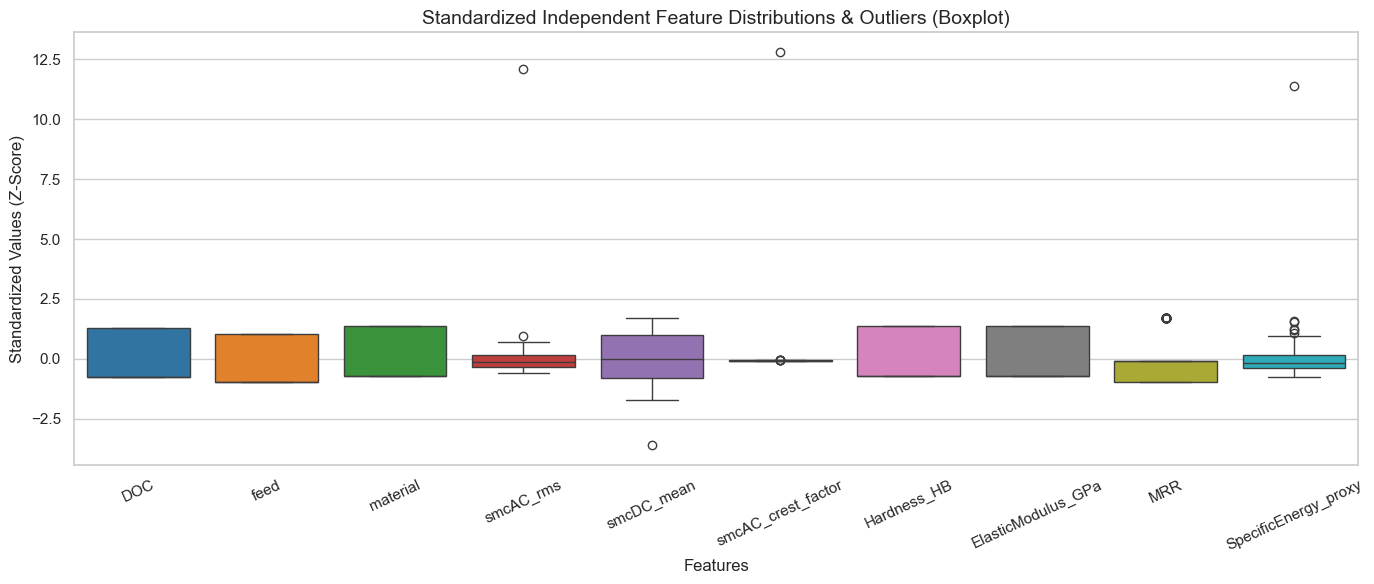

In [3]:
# ==============================================================================
# Cell 3: Outlier Inspection on Independent Features (IQR Method & Boxplot)
# ==============================================================================


def detect_outliers_iqr(df: pd.DataFrame, columns: List[str]) -> pd.Series:
    """Calculate statistical outlier counts using the 1.5 * IQR rule.

    Evaluates independent input features only (zero target leakage).
    """
    q1 = df[columns].quantile(0.25)
    q3 = df[columns].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    is_outlier = (df[columns] < lower_limit) | (df[columns] > upper_limit)
    return is_outlier.sum()


print("=== Outlier Count per Independent Feature (IQR 1.5x) ===")
print(detect_outliers_iqr(df_filtered, feature_columns))

# Standardized Z-Score visualization for independent feature distributions
df_features_only = df_filtered[feature_columns]
standardized_features = (
    df_features_only - df_features_only.mean()
) / df_features_only.std()

plt.figure(figsize=(14, 6))
sns.boxplot(data=standardized_features, palette="tab10")
plt.title(
    "Standardized Independent Feature Distributions & Outliers (Boxplot)",
    fontsize=14,
)
plt.ylabel("Standardized Values (Z-Score)")
plt.xlabel("Features")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

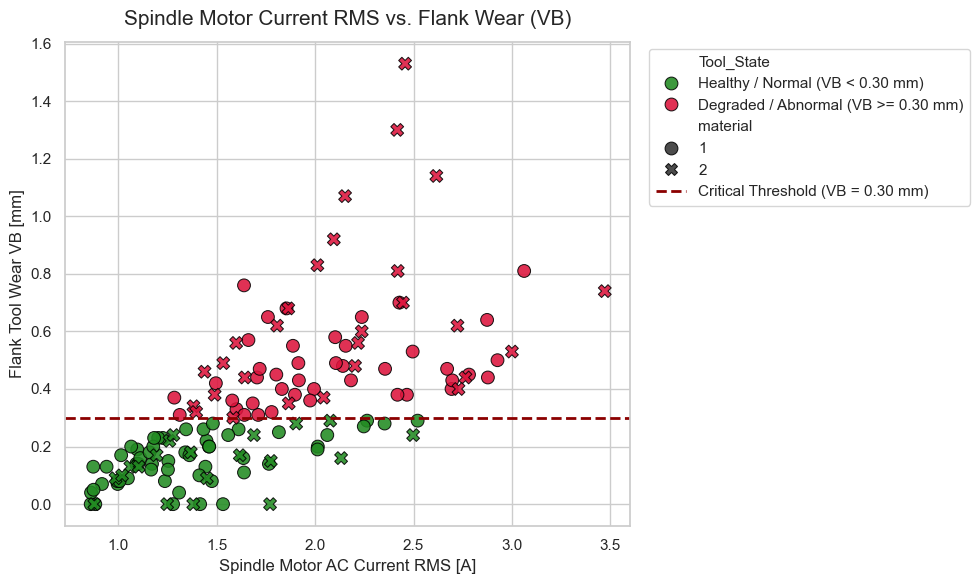

Sample breakdown: 75 Normal | 70 Degraded


In [4]:
# ==============================================================================
# Cell 4: Scatter Plot — smcAC_rms vs VB with Critical Wear Boundary (0.30 mm)
# ==============================================================================

# Isolate valid VB measurements (exclude unmeasured NaN runs)
df_scatter = df_filtered.dropna(subset=["VB"]).copy()

CRITICAL_VB_THRESHOLD: float = 0.30  # Critical tool flank wear limit (mm)

# Categorize operational condition based on critical boundary
df_scatter["Tool_State"] = np.where(
    df_scatter["VB"] >= CRITICAL_VB_THRESHOLD,
    f"Degraded / Abnormal (VB >= {CRITICAL_VB_THRESHOLD:.2f} mm)",
    f"Healthy / Normal (VB < {CRITICAL_VB_THRESHOLD:.2f} mm)",
)

plt.figure(figsize=(10, 6))
palette_colors = {
    f"Healthy / Normal (VB < {CRITICAL_VB_THRESHOLD:.2f} mm)": "forestgreen",
    f"Degraded / Abnormal (VB >= {CRITICAL_VB_THRESHOLD:.2f} mm)": "crimson",
}

scatter_ax = sns.scatterplot(
    data=df_scatter,
    x="smcAC_rms",
    y="VB",
    hue="Tool_State",
    style="material",
    palette=palette_colors,
    s=85,
    alpha=0.88,
    edgecolor="black",
)

# Draw horizontal critical boundary
scatter_ax.axhline(
    CRITICAL_VB_THRESHOLD,
    color="darkred",
    linestyle="--",
    linewidth=2.0,
    label=f"Critical Threshold (VB = {CRITICAL_VB_THRESHOLD:.2f} mm)",
)

scatter_ax.set_title(
    "Spindle Motor Current RMS vs. Flank Wear (VB)", fontsize=15, pad=12
)
scatter_ax.set_xlabel("Spindle Motor AC Current RMS [A]", fontsize=12)
scatter_ax.set_ylabel("Flank Tool Wear VB [mm]", fontsize=12)
scatter_ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

normal_count = (df_scatter["VB"] < CRITICAL_VB_THRESHOLD).sum()
abnormal_count = (df_scatter["VB"] >= CRITICAL_VB_THRESHOLD).sum()
print(f"Sample breakdown: {normal_count} Normal | {abnormal_count} Degraded")

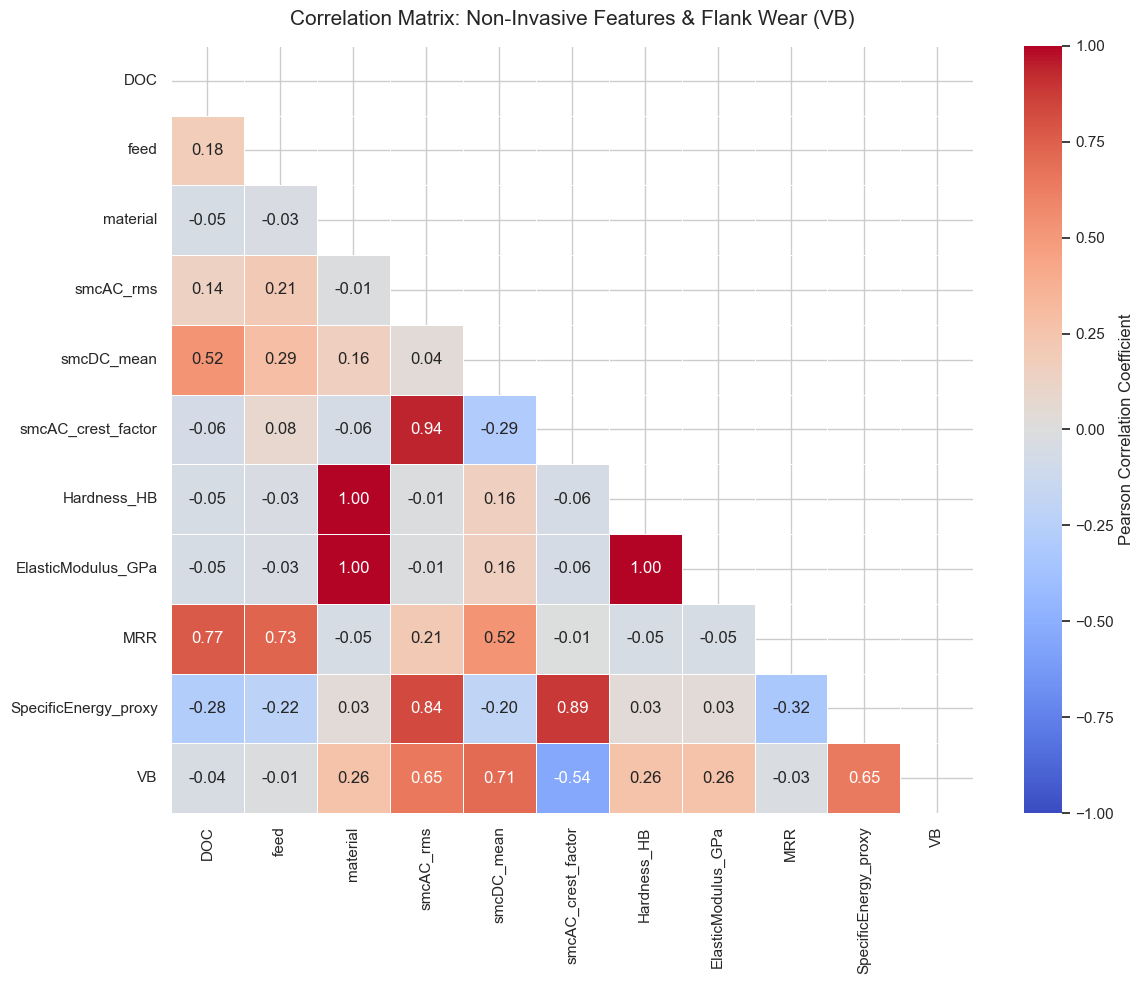

FEATURE CORRELATION RANKING WITH TARGET (VB)
VB                      1.000000
smcDC_mean              0.705981
smcAC_rms               0.653782
SpecificEnergy_proxy    0.646072
Hardness_HB             0.257938
material                0.257938
ElasticModulus_GPa      0.257938
feed                   -0.012702
MRR                    -0.025084
DOC                    -0.039188
smcAC_crest_factor     -0.543591
Name: VB, dtype: float64


In [5]:
# ==============================================================================
# Cell 5: Correlation Matrix Heatmap
# ==============================================================================

# Include both independent features and the target variable for relationship audit
analysis_columns = feature_columns + [target_column]
corr_matrix = df_filtered[analysis_columns].corr(method="pearson")

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    mask=mask,
    linewidths=0.6,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
)

plt.title(
    "Correlation Matrix: Non-Invasive Features & Flank Wear (VB)",
    fontsize=15,
    pad=15,
)
plt.tight_layout()
plt.show()

print("=" * 60)
print("FEATURE CORRELATION RANKING WITH TARGET (VB)")
print("=" * 60)
print(corr_matrix[target_column].sort_values(ascending=False))

In [6]:
# ==============================================================================
# Cell 6: Data Preprocessing, Stratified Split (60/20/20), and Scaling
# ==============================================================================
from typing import List, Tuple
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Drop rows with unmeasured wear (NaN in VB)
df_labeled = df_filtered.dropna(subset=["VB"]).copy().reset_index(drop=True)

# 2. Construct binary classification target:
# 1 = Worn / Fail (VB >= 0.30 mm), 0 = Healthy (VB < 0.30 mm)
CRITICAL_THRESHOLD_MM: float = 0.30
df_labeled["tool_worn"] = (df_labeled["VB"] >= CRITICAL_THRESHOLD_MM).astype(
    int
)

# 3. Prevent target leakage: Drop identifiers, raw targets, and redundant categorical labels
leakage_columns_to_drop: List[str] = [
    "case",
    "run",
    "material",
    "VB",
    "tool_worn",
]
X: pd.DataFrame = df_labeled.drop(
    columns=[col for col in leakage_columns_to_drop if col in df_labeled.columns]
)
y: pd.Series = df_labeled["tool_worn"]

feature_names: List[str] = list(X.columns)

print("=" * 60)
print("PREPROCESSED DATASET SUMMARY")
print("=" * 60)
print(f"Total labeled samples: {len(X)}")
print(f"Isolated feature matrix shape: {X.shape}")
print(f"Features: {feature_names}")
print(
    f"Class distribution: Healthy (0) = {(y == 0).sum()} | Worn (1) = {(y == 1).sum()}"
)

# 4. Stratified Split: 60% Train, 20% Validation, 20% Test
# Step A: Split into temporary train+val (80%) and test (20%)
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Step B: Split train+val into train (60% total) and validation (20% total)
# 20% of total is 0.20 / 0.80 = 0.25 (25%) of train+val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25, stratify=y_train_val, random_state=42
)

print("\n" + "=" * 60)
print("STRATIFIED DATA SPLIT RATIOS")
print("=" * 60)
print(
    f"Training set:   {X_train.shape[0]} samples ({X_train.shape[0] / len(X):.1%})"
)
print(
    f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0] / len(X):.1%})"
)
print(
    f"Test set:       {X_test.shape[0]} samples ({X_test.shape[0] / len(X):.1%})"
)

# 5. Fit StandardScaler strictly on the training set to prevent data snooping
scaler = StandardScaler()

# Transform all splits while preserving DataFrame column names and indices
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train), columns=feature_names, index=X_train.index
)
X_val_scaled = pd.DataFrame(
    scaler.transform(X_val), columns=feature_names, index=X_val.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test), columns=feature_names, index=X_test.index
)

print("\n" + "=" * 60)
print("SCALER PARAMETERS (FITTED ON TRAIN ONLY)")
print("=" * 60)
scaler_summary = pd.DataFrame(
    {"Feature": feature_names, "Mean": scaler.mean_, "Std": scaler.scale_}
).set_index("Feature")
print(scaler_summary)

PREPROCESSED DATASET SUMMARY
Total labeled samples: 145
Isolated feature matrix shape: (145, 9)
Features: ['DOC', 'feed', 'smcAC_rms', 'smcDC_mean', 'smcAC_crest_factor', 'Hardness_HB', 'ElasticModulus_GPa', 'MRR', 'SpecificEnergy_proxy']
Class distribution: Healthy (0) = 75 | Worn (1) = 70

STRATIFIED DATA SPLIT RATIOS
Training set:   87 samples (60.0%)
Validation set: 29 samples (20.0%)
Test set:       29 samples (20.0%)

SCALER PARAMETERS (FITTED ON TRAIN ONLY)
                            Mean        Std
Feature                                    
DOC                     1.008621   0.356484
feed                    0.362069   0.124329
smcAC_rms               1.662555   0.518805
smcDC_mean              5.991869   1.539630
smcAC_crest_factor      2.286990   0.137733
Hardness_HB           207.873563  18.687266
ElasticModulus_GPa    138.965517  42.046348
MRR                    74.137931  39.790810
SpecificEnergy_proxy    0.026247   0.010079


VALIDATION SET MODEL PERFORMANCE COMPARISON
Dummy Baseline (Most Frequent) Accuracy: 0.5172
Logistic Regression Accuracy:            0.8966
Absolute Accuracy Improvement:          +0.3793

LOGISTIC REGRESSION CLASSIFICATION REPORT (VALIDATION SET)
              precision    recall  f1-score   support

 Healthy (0)     0.9286    0.8667    0.8966        15
    Worn (1)     0.8667    0.9286    0.8966        14

    accuracy                         0.8966        29
   macro avg     0.8976    0.8976    0.8966        29
weighted avg     0.8987    0.8966    0.8966        29



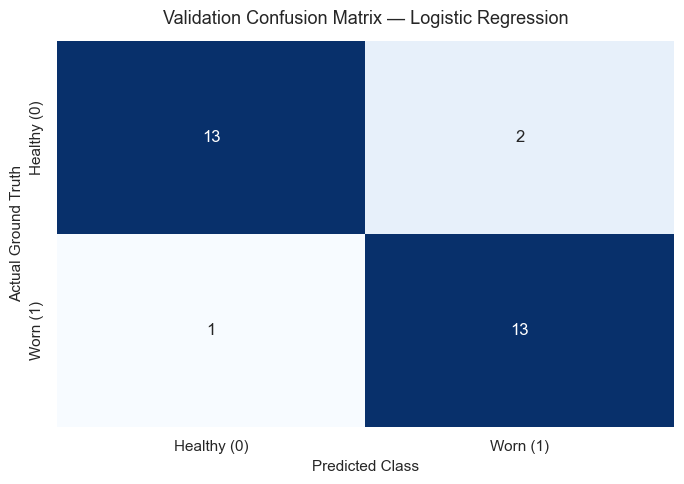

In [7]:
# ==============================================================================
# Cell 7: Baseline Benchmark (DummyClassifier) vs. LogisticRegression on Validation Set
# ==============================================================================
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# 1. Instantiate and train DummyClassifier baseline (strategy='most_frequent')
dummy_baseline = DummyClassifier(strategy="most_frequent")
dummy_baseline.fit(X_train_scaled, y_train)

# Predict strictly on validation set
y_val_pred_dummy = dummy_baseline.predict(X_val_scaled)
dummy_val_accuracy = accuracy_score(y_val, y_val_pred_dummy)

# 2. Instantiate and train LogisticRegression model
# Configured with max_iter=1000, random_state=42, and class_weight='balanced'
logistic_model = LogisticRegression(
    max_iter=1000, random_state=42, class_weight="balanced"
)
logistic_model.fit(X_train_scaled, y_train)

# Predict strictly on validation set (test set remains untouched)
y_val_pred_lr = logistic_model.predict(X_val_scaled)
lr_val_accuracy = accuracy_score(y_val, y_val_pred_lr)

# 3. Accuracy comparison
print("=" * 65)
print("VALIDATION SET MODEL PERFORMANCE COMPARISON")
print("=" * 65)
print(f"Dummy Baseline (Most Frequent) Accuracy: {dummy_val_accuracy:.4f}")
print(f"Logistic Regression Accuracy:            {lr_val_accuracy:.4f}")
print(
    f"Absolute Accuracy Improvement:          +{lr_val_accuracy - dummy_val_accuracy:.4f}"
)

# 4. Detailed Classification Report for Logistic Regression
target_class_names = ["Healthy (0)", "Worn (1)"]
print("\n" + "=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT (VALIDATION SET)")
print("=" * 65)
print(
    classification_report(
        y_val,
        y_val_pred_lr,
        target_names=target_class_names,
        digits=4,
    )
)

# 5. Confusion Matrix Visualization
val_conf_matrix = confusion_matrix(y_val, y_val_pred_lr)

plt.figure(figsize=(7, 5))
sns.heatmap(
    val_conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=target_class_names,
    yticklabels=target_class_names,
)
plt.title("Validation Confusion Matrix — Logistic Regression", fontsize=13, pad=12)
plt.xlabel("Predicted Class", fontsize=11)
plt.ylabel("Actual Ground Truth", fontsize=11)
plt.tight_layout()
plt.show()

MODEL INTERCEPT (BIAS): -0.2882
STANDARDIZED FEATURE IMPORTANCE RANKING (BY ABSOLUTE MAGNITUDE)
                Feature  Coefficient  Abs_Coefficient                Feature_Type         Impact_Direction
0            smcDC_mean     1.628845         1.628845  Motor Current / Electrical  Increases Wear Risk (+)
1             smcAC_rms     1.491410         1.491410  Motor Current / Electrical  Increases Wear Risk (+)
2  SpecificEnergy_proxy     1.256897         1.256897  Motor Current / Electrical  Increases Wear Risk (+)
3                   MRR    -0.988536         0.988536          Process / Material  Decreases Wear Risk (-)
4                   DOC    -0.606112         0.606112          Process / Material  Decreases Wear Risk (-)
5    smcAC_crest_factor    -0.332802         0.332802  Motor Current / Electrical  Decreases Wear Risk (-)
6                  feed     0.306567         0.306567          Process / Material  Increases Wear Risk (+)
7    ElasticModulus_GPa     0.166763         0.1

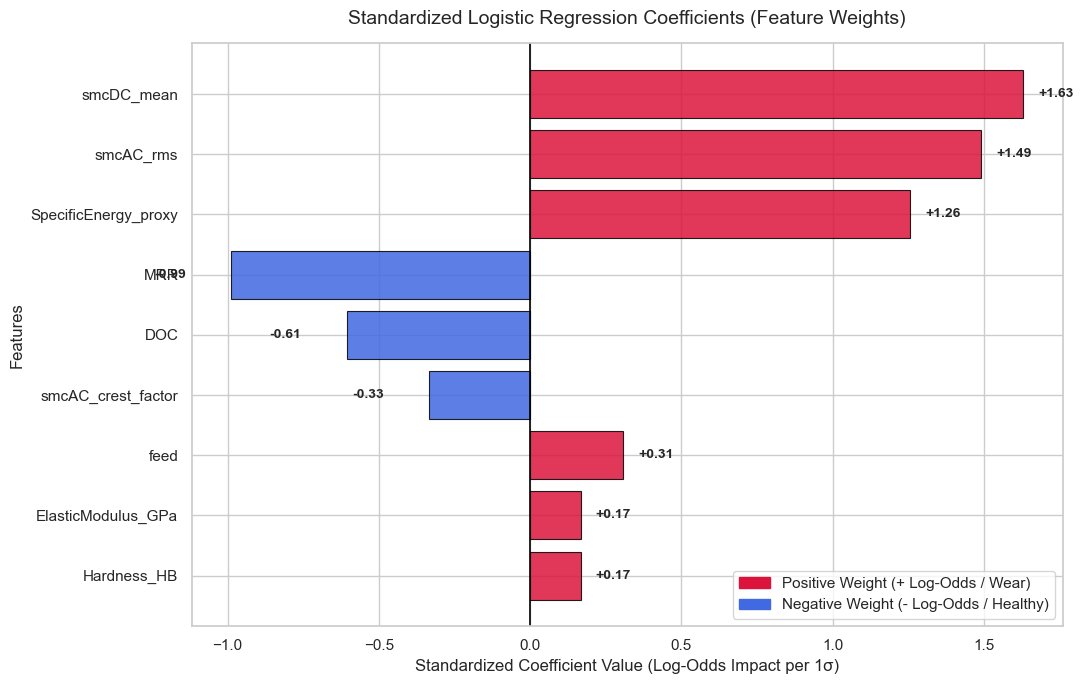


FEATURE GROUP SUMMARY: MOTOR CURRENT VS. PROCESS PARAMETERS
                            Mean |Weight|  Total |Weight|  Peak |Weight|  Feature Count
Feature_Type                                                                           
Motor Current / Electrical       1.177489        4.709954       1.628845              4
Process / Material               0.446948        2.234740       0.988536              5


In [8]:
# ==============================================================================
# Cell 8: Standardized Coefficient Extraction, Ranking, and Feature Impact Analysis
# ==============================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Extract standardized coefficients from the trained Logistic Regression model
coefficients: np.ndarray = logistic_model.coef_[0]
intercept: float = float(logistic_model.intercept_[0])

# Categorize feature types to compare motor current vs. process parameters
motor_features = {
    "smcAC_rms",
    "smcDC_mean",
    "smcAC_crest_factor",
    "SpecificEnergy_proxy",
}

feature_importance_df = pd.DataFrame(
    {
        "Feature": feature_names,
        "Coefficient": coefficients,
        "Abs_Coefficient": np.abs(coefficients),
        "Feature_Type": [
            "Motor Current / Electrical"
            if f in motor_features
            else "Process / Material"
            for f in feature_names
        ],
        "Impact_Direction": [
            "Increases Wear Risk (+)"
            if c > 0
            else "Decreases Wear Risk (-)"
            for c in coefficients
        ],
    }
).sort_values(by="Abs_Coefficient", ascending=True)

# 2. Display formatted coefficient table
print("=" * 80)
print(f"MODEL INTERCEPT (BIAS): {intercept:.4f}")
print("STANDARDIZED FEATURE IMPORTANCE RANKING (BY ABSOLUTE MAGNITUDE)")
print("=" * 80)
display_table = feature_importance_df.sort_values(
    by="Abs_Coefficient", ascending=False
).reset_index(drop=True)
print(
    display_table[
        [
            "Feature",
            "Coefficient",
            "Abs_Coefficient",
            "Feature_Type",
            "Impact_Direction",
        ]
    ].to_string(index=True)
)

# 3. Horizontal Bar Chart of Standardized Model Coefficients
plt.figure(figsize=(11, 7))

# Distinguish positive (wear-inducing) vs negative (healthy-indicating) weights
colors = [
    "crimson" if c > 0 else "royalblue"
    for c in feature_importance_df["Coefficient"]
]

bars = plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Coefficient"],
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    alpha=0.85,
)

# Annotate each bar with its exact coefficient value
for bar, val in zip(bars, feature_importance_df["Coefficient"]):
    x_pos = val + (0.05 if val >= 0 else -0.15)
    plt.text(
        x_pos,
        bar.get_y() + bar.get_height() / 2,
        f"{val:+.2f}",
        va="center",
        ha="left" if val >= 0 else "right",
        fontsize=10,
        fontweight="bold",
    )

# Formatting references and legends
plt.axvline(0, color="black", linestyle="-", linewidth=1.2)
plt.title(
    "Standardized Logistic Regression Coefficients (Feature Weights)",
    fontsize=14,
    pad=14,
)
plt.xlabel(
    "Standardized Coefficient Value (Log-Odds Impact per 1σ)", fontsize=12
)
plt.ylabel("Features", fontsize=12)

# Custom legend for impact direction
custom_handles = [
    plt.Rectangle(
        (0, 0),
        1,
        1,
        color="crimson",
        label="Positive Weight (+ Log-Odds / Wear)",
    ),
    plt.Rectangle(
        (0, 0),
        1,
        1,
        color="royalblue",
        label="Negative Weight (- Log-Odds / Healthy)",
    ),
]
plt.legend(handles=custom_handles, loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

# 4. Grouped comparison: Motor Current vs. Process Parameters
grouped_importance = (
    feature_importance_df.groupby("Feature_Type")["Abs_Coefficient"]
    .agg(["mean", "sum", "max", "count"])
    .rename(
        columns={
            "mean": "Mean |Weight|",
            "sum": "Total |Weight|",
            "max": "Peak |Weight|",
            "count": "Feature Count",
        }
    )
)

print("\n" + "=" * 80)
print("FEATURE GROUP SUMMARY: MOTOR CURRENT VS. PROCESS PARAMETERS")
print("=" * 80)
print(grouped_importance.to_string())

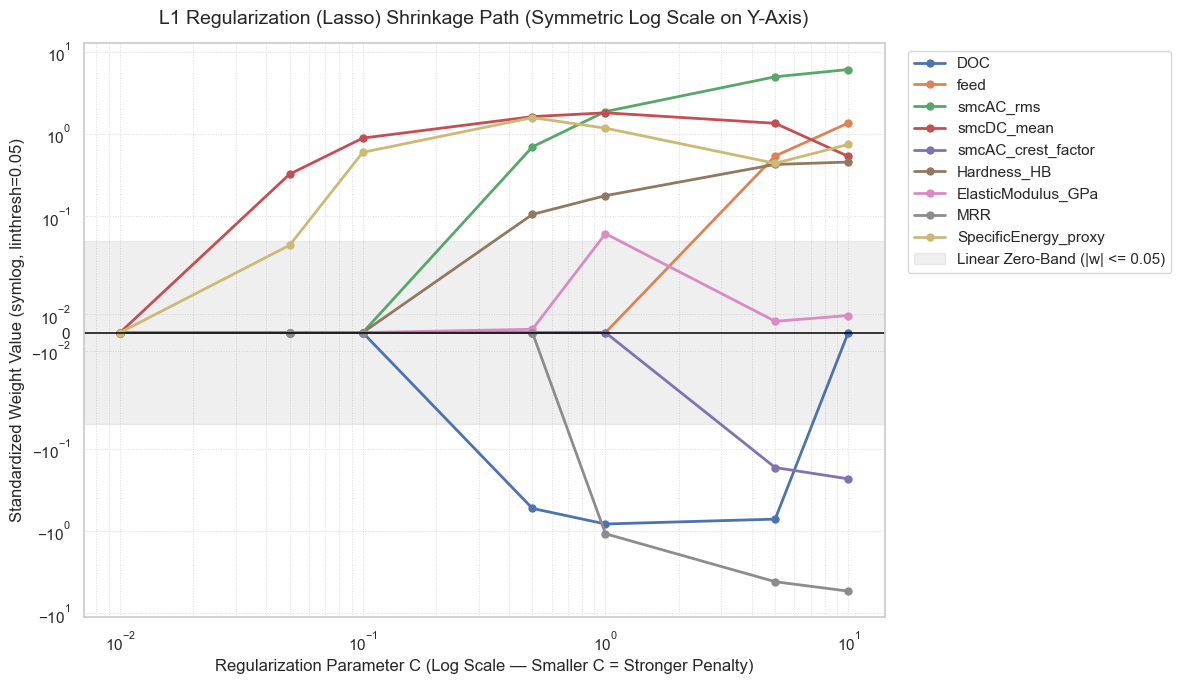

LASSO HYPERPARAMETER SUMMARY (BEST C = 1.0, VAL ACCURACY = 0.8966)
       val_accuracy     DOC    feed  smcAC_rms  smcDC_mean  smcAC_crest_factor  Hardness_HB  ElasticModulus_GPa     MRR  SpecificEnergy_proxy
C                                                                                                                                            
0.01         0.5172  0.0000  0.0000     0.0000      0.0000              0.0000       0.0000              0.0000  0.0000                0.0000
0.05         0.8276  0.0000  0.0000     0.0000      0.3268              0.0000       0.0000              0.0000  0.0000                0.0478
0.10         0.8276  0.0000  0.0000     0.0000      0.8948              0.0000       0.0000              0.0000  0.0000                0.6005
0.50         0.8621 -0.5310  0.0000     0.7003      1.6329              0.0000       0.1058              0.0018  0.0000                1.5887
1.00         0.8966 -0.8207  0.0000     1.8824      1.8170              0.0000   

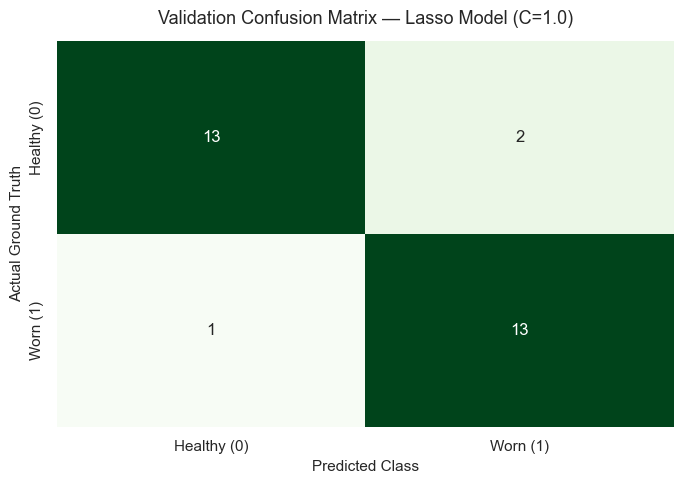

In [9]:
# ==============================================================================
# Cell 9: L1-Regularized (Lasso) Logistic Regression with Symmetric Log Path Plot
# ==============================================================================
from typing import Dict, List, Tuple
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# 1. Hyperparameter candidate grid for inverse regularization strength C
C_candidates: List[float] = [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]

path_records: List[Dict[str, float]] = []
models_dict: Dict[float, LogisticRegression] = {}
val_accuracies: Dict[float, float] = {}

# 2. Train L1-regularized models across the C grid and evaluate on validation set
for c_val in C_candidates:
    lasso_model = LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=c_val,
        class_weight="balanced",
        random_state=42,
        max_iter=1000,
    )
    lasso_model.fit(X_train_scaled, y_train)
    models_dict[c_val] = lasso_model

    # Validation prediction
    y_val_pred = lasso_model.predict(X_val_scaled)
    acc = accuracy_score(y_val, y_val_pred)
    val_accuracies[c_val] = acc

    # Track coefficient shrinkage per feature
    coef_entry = {"C": c_val, "val_accuracy": acc}
    for feature_name, coef_val in zip(feature_names, lasso_model.coef_[0]):
        coef_entry[feature_name] = float(coef_val)
    path_records.append(coef_entry)

df_lasso_path = pd.DataFrame(path_records).set_index("C")

# 3. Plot L1 Shrinkage Path using Symmetric Log Scale (symlog) on Y-axis
LINTHRESH_COEF: float = 0.05

plt.figure(figsize=(12, 7))

for feature in feature_names:
    plt.plot(
        df_lasso_path.index,
        df_lasso_path[feature],
        marker="o",
        markersize=5,
        linewidth=2.0,
        label=feature,
    )

# Horizontal axis: standard log scale for hyperparameter C
plt.xscale("log")

# Vertical axis: symmetric log scale (symlog) for positive, negative, and zero weights
plt.yscale("symlog", linthresh=LINTHRESH_COEF, linscale=1.0)

# Reference boundary lines
plt.axhline(0.0, color="black", linestyle="-", linewidth=1.2, alpha=0.9)
plt.axhspan(
    -LINTHRESH_COEF,
    LINTHRESH_COEF,
    color="gray",
    alpha=0.12,
    label=f"Linear Zero-Band (|w| <= {LINTHRESH_COEF})",
)

plt.title(
    "L1 Regularization (Lasso) Shrinkage Path (Symmetric Log Scale on Y-Axis)",
    fontsize=14,
    pad=14,
)
plt.xlabel(
    "Regularization Parameter C (Log Scale — Smaller C = Stronger Penalty)",
    fontsize=12,
)
plt.ylabel(
    f"Standardized Weight Value (symlog, linthresh={LINTHRESH_COEF})",
    fontsize=12,
)
plt.grid(True, which="both", linestyle=":", linewidth=0.7, alpha=0.7)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()

# 4. Identify Best Performing C on the Validation Set
best_c = max(val_accuracies, key=lambda c: (val_accuracies[c], -c))
best_lasso_model = models_dict[best_c]
y_val_pred_best = best_lasso_model.predict(X_val_scaled)

print("=" * 75)
print(
    f"LASSO HYPERPARAMETER SUMMARY (BEST C = {best_c}, VAL ACCURACY = {val_accuracies[best_c]:.4f})"
)
print("=" * 75)
path_summary = df_lasso_path[["val_accuracy"] + feature_names]
print(path_summary.round(4).to_string())

# 5. Sparsity Audit: Identify zeroed-out vs. retained active features
best_coefs = pd.Series(best_lasso_model.coef_[0], index=feature_names)
eliminated_features = best_coefs[best_coefs == 0.0].index.tolist()
retained_features = (
    best_coefs[best_coefs != 0.0].abs().sort_values(ascending=False).index.tolist()
)

print("\n" + "=" * 75)
print("FEATURE SPARSITY AUDIT AT OPTIMAL REGULARIZATION")
print("=" * 75)
print(f"Total Features Evaluated: {len(feature_names)}")
print(f"Retained Active Features ({len(retained_features)}): {retained_features}")
print(
    f"Eliminated Zero-Weight Features ({len(eliminated_features)}): {eliminated_features}"
)

# 6. Final Model Validation Evaluation
print("\n" + "=" * 75)
print(f"CLASSIFICATION REPORT (BEST LASSO MODEL: C = {best_c})")
print("=" * 75)
print(
    classification_report(
        y_val,
        y_val_pred_best,
        target_names=["Healthy (0)", "Worn (1)"],
        digits=4,
    )
)

# 7. Confusion Matrix Visualization
plt.figure(figsize=(7, 5))
cm_lasso = confusion_matrix(y_val, y_val_pred_best)
sns.heatmap(
    cm_lasso,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=["Healthy (0)", "Worn (1)"],
    yticklabels=["Healthy (0)", "Worn (1)"],
)
plt.title(
    f"Validation Confusion Matrix — Lasso Model (C={best_c})",
    fontsize=13,
    pad=12,
)
plt.xlabel("Predicted Class", fontsize=11)
plt.ylabel("Actual Ground Truth", fontsize=11)
plt.tight_layout()
plt.show()

5-FOLD CROSS-VALIDATION GRID SEARCH RESULTS (OPTIMIZING F1-SCORE)
Best Hyperparameter (C): 1.0
Best 5-Fold Mean CV F1:  0.8907
    C  Mean CV F1  Std CV F1  Train F1 (Fold Avg)  Rank
  1.0    0.890691   0.092028             0.911821     1
  5.0    0.880165   0.081309             0.934052     2
 10.0    0.880165   0.081309             0.934052     2
  0.5    0.879561   0.055214             0.887205     4
  0.1    0.854326   0.023955             0.857120     5
 0.05    0.620261   0.311293             0.642180     6
 0.01    0.000000   0.000000             0.000000     7


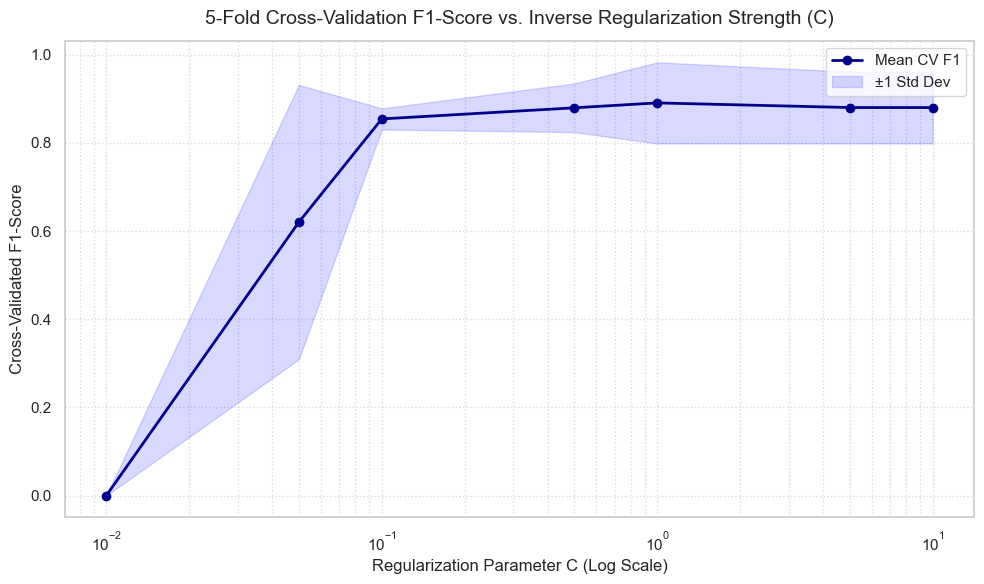


VALIDATION SET EVALUATION WITH BEST CV MODEL (C = 1.0)
Validation F1-Score: 0.8966

              precision    recall  f1-score   support

 Healthy (0)     0.9286    0.8667    0.8966        15
    Worn (1)     0.8667    0.9286    0.8966        14

    accuracy                         0.8966        29
   macro avg     0.8976    0.8976    0.8966        29
weighted avg     0.8987    0.8966    0.8966        29



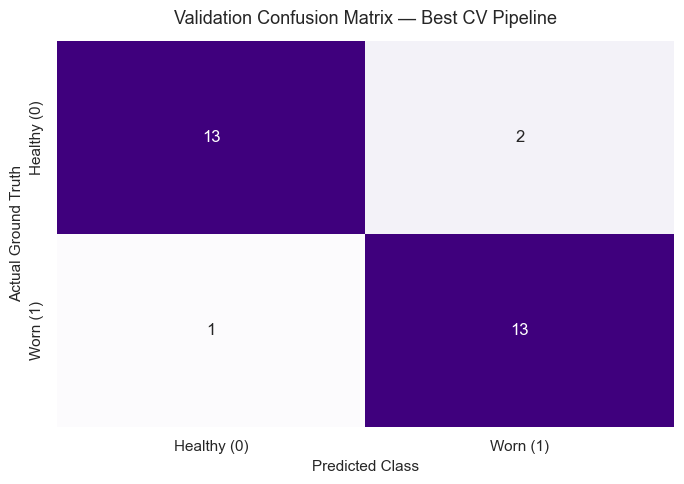

In [10]:
# ==============================================================================
# Cell 10: 5-Fold Stratified Cross-Validation on X_train with GridSearchCV (F1-Score)
# ==============================================================================
from typing import Any, Dict, List
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Construct a leak-free Pipeline
# Ensures StandardScaler fits strictly on each training fold during cross-validation
pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "classifier",
            LogisticRegression(
                penalty="l1",
                solver="liblinear",
                class_weight="balanced",
                random_state=42,
                max_iter=1000,
            ),
        ),
    ]
)

# 2. Hyperparameter grid for inverse regularization strength C
param_grid: Dict[str, List[float]] = {
    "classifier__C": [0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]
}

# 3. Stratified 5-Fold Cross-Validation strategy
stratified_5fold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 4. Instantiate GridSearchCV targeting the F1 metric
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=stratified_5fold,
    scoring="f1",
    return_train_score=True,
    n_jobs=-1,
)

# Fit strictly on the training partition (X_train, y_train)
grid_search.fit(X_train, y_train)

# 5. Tabulate Cross-Validation Results
cv_results_df = pd.DataFrame(grid_search.cv_results_)
summary_cv = cv_results_df[
    [
        "param_classifier__C",
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "rank_test_score",
    ]
].rename(
    columns={
        "param_classifier__C": "C",
        "mean_test_score": "Mean CV F1",
        "std_test_score": "Std CV F1",
        "mean_train_score": "Train F1 (Fold Avg)",
        "rank_test_score": "Rank",
    }
).sort_values(by="Rank").reset_index(drop=True)

print("=" * 75)
print("5-FOLD CROSS-VALIDATION GRID SEARCH RESULTS (OPTIMIZING F1-SCORE)")
print("=" * 75)
print(f"Best Hyperparameter (C): {grid_search.best_params_['classifier__C']}")
print(f"Best 5-Fold Mean CV F1:  {grid_search.best_score_:.4f}")
print("=" * 75)
print(summary_cv.to_string(index=False))

# 6. Plot CV Performance vs Regularization Parameter C
plt.figure(figsize=(10, 6))
c_values = cv_results_df["param_classifier__C"].astype(float)
mean_f1 = cv_results_df["mean_test_score"]
std_f1 = cv_results_df["std_test_score"]

plt.plot(c_values, mean_f1, marker="o", color="darkblue", linewidth=2.0, label="Mean CV F1")
plt.fill_between(
    c_values,
    mean_f1 - std_f1,
    mean_f1 + std_f1,
    color="blue",
    alpha=0.15,
    label="±1 Std Dev",
)

plt.xscale("log")
plt.title("5-Fold Cross-Validation F1-Score vs. Inverse Regularization Strength (C)", fontsize=14, pad=12)
plt.xlabel("Regularization Parameter C (Log Scale)", fontsize=12)
plt.ylabel("Cross-Validated F1-Score", fontsize=12)
plt.grid(True, which="both", linestyle=":", alpha=0.7)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

# 7. Evaluate the Best CV Estimator on the Untouched Validation Set
best_pipeline = grid_search.best_estimator_
y_val_pred_cv = best_pipeline.predict(X_val)

val_f1 = f1_score(y_val, y_val_pred_cv)
print("\n" + "=" * 75)
print(f"VALIDATION SET EVALUATION WITH BEST CV MODEL (C = {grid_search.best_params_['classifier__C']})")
print("=" * 75)
print(f"Validation F1-Score: {val_f1:.4f}")
print("\n" + classification_report(
    y_val,
    y_val_pred_cv,
    target_names=["Healthy (0)", "Worn (1)"],
    digits=4,
))

# 8. Confusion Matrix on Validation Set
plt.figure(figsize=(7, 5))
cm_val_cv = confusion_matrix(y_val, y_val_pred_cv)
sns.heatmap(
    cm_val_cv,
    annot=True,
    fmt="d",
    cmap="Purples",
    cbar=False,
    xticklabels=["Healthy (0)", "Worn (1)"],
    yticklabels=["Healthy (0)", "Worn (1)"],
)
plt.title(f"Validation Confusion Matrix — Best CV Pipeline", fontsize=13, pad=12)
plt.xlabel("Predicted Class", fontsize=11)
plt.ylabel("Actual Ground Truth", fontsize=11)
plt.tight_layout()
plt.show()

In [11]:
!git init
!git branch -M main
!git add .
!git commit -m "Initial commit: ME405 Project Repository Interim Report Ready."
!git remote add origin https://github.com/NecatBerkMeral/ME405_Project.git
!git push -u origin main

Initialized empty Git repository in C:/Users/necat/.git/
^C


fatal: Unable to create 'C:/Users/necat/.git/index.lock': File exists.

Another git process seems to be running in this repository, e.g.
an editor opened by 'git commit'. Please make sure all processes
are terminated then try again. If it still fails, a git process
may have crashed in this repository earlier:
remove the file manually to continue.
error: src refspec main does not match any
error: failed to push some refs to 'https://github.com/NecatBerkMeral/ME405_Project.git'
